# 09 · Observabilidad: Langfuse y LangSmith

Un sistema RAG que funciona el día que lo despliegas se desviará con el tiempo: los documentos cambian, los
usuarios preguntan cosas nuevas, un proveedor cambia un modelo, alguien edita un prompt. Los módulos 07 y 08
juzgan las respuestas por lotes. La **observabilidad** es la capa que está debajo y que hace posibles esos
juicios: una **traza** de cada petición que registra qué se recuperó, qué prompt vio el modelo, qué respondió,
cuántos tokens usó, cuánto tardó cada paso, cuánto costó y qué puntuaciones se le asociaron después.

Este módulo construye desde cero un trazador diminuto que funciona sin conexión (para que veas cada pieza), lo
equipara uno a uno con el vocabulario de **Langfuse** (la herramienta de código abierto para trazar LLM que se
usa en este portafolio), muestra el código real de Langfuse en una celda opcional que **aquí no se ejecuta**, y
después examina **LangSmith**, la otra herramienta por la que todo el mundo pregunta, y por qué no la necesitamos.

**Aprenderás**
1. Qué registrar en una aplicación con LLM, y el vocabulario: traza, tramo (span), generación, puntuación, sesión
2. Un trazador basado en decoradores, con conteo de tokens y coste a partir de una tabla de precios
3. Asociar a las trazas puntuaciones de estilo supervisor
4. Leer un panel: coste por respuesta, percentiles de latencia, tokens, tasa de rechazo
5. Encontrar las peores trazas, la verdadera recompensa de trazar
6. El SDK real de Langfuse (con LiteLLM y LangChain) y cómo se compara LangSmith

## 1. Qué es una traza

Piensa en una traza como la caja negra de una petición:

| Término de Langfuse | Significado | En nuestro pipeline RAG |
|---|---|---|
| **Traza** (trace) | una petición de principio a fin | toda la llamada "responde esta pregunta" |
| **Tramo** (span) | un paso cronometrado dentro de la traza | `retrieve`, `build_prompt` |
| **Generación** (generation) | un tramo que es una llamada a un modelo: nombre del modelo, entrada, salida, uso de tokens, coste | `generate` |
| **Puntuación** (score) | un número o etiqueta asociado a una traza o a un tramo | `correct`, `faithfulness`, `refused` |
| **Sesión** (session) | un grupo de trazas de una misma conversación | cuatro preguntas seguidas de un usuario |

Los tramos se anidan: la traza contiene el tramo de recuperación y la generación. Con esa estructura puedes
responder preguntas que ninguna línea de log permite: *¿qué paso es lento?, ¿qué preguntas cuestan más?, ¿qué
respuestas estaban mal respaldadas?, ¿qué vio exactamente el modelo cuando se equivocó en esta?*

## 2. Un trazador en cuarenta líneas

Primero el pipeline que queremos observar: el manual de Harbourview, la recuperación BM25 y el mismo generador
extractivo de sustitución del módulo 01 (en este notebook no se llama a ningún modelo). Después, el trazador.

Como el generador es un sustituto, **la latencia aquí es simulada** con un reloj virtual (a una llamada a un
modelo se le carga una sobrecarga fija más un tiempo por token de salida, con ruido con semilla). Lo que importa
es la contabilidad, no la velocidad de un proveedor real, y un reloj virtual además hace que cada ejecución del
notebook sea idéntica. Los tokens se estiman a 1,3 por palabra, la regla aproximada habitual para el inglés; un
proveedor real devuelve los recuentos exactos en su respuesta y deberías registrar esos.

In [1]:
# The Harbourview handbook: 22 passages, fictional, written for this course
PASSAGES = [
    ["p01", "Safety / Access", "Technicians must hold a valid GWO Basic Safety Training certificate before boarding a crew transfer vessel. Certificates are checked at the harbour gate and expire after two years."],
    ["p02", "Safety / Weather limits", "Crew transfer vessels do not sail when the significant wave height exceeds 1.5 m or the wind speed at the harbour exceeds 20 m/s. The duty coordinator decides at 06:00 and may cancel later."],
    ["p03", "Safety / Lone working", "Lone working inside a nacelle is forbidden. Every task inside a turbine needs at least two people, and both must carry a personal locator beacon."],
    ["p04", "Turbines / Specification", "Each of the 40 turbines is rated at 8.0 MW with a rotor diameter of 164 m. Cut-in wind speed is 3 m/s, rated speed is 12.5 m/s and cut-out speed is 25 m/s."],
    ["p05", "Turbines / Naming", "Turbines are named HV01 to HV40, numbered from the western edge of the array. The offshore substation is OSS1, in the centre."],
    ["p06", "Maintenance / Schedule", "Every turbine gets a planned service once a year between April and September. The service takes two technicians about two days, plus weather delays."],
    ["p07", "Maintenance / Gearbox oil", "Gearbox oil is sampled every six months. If the particle count exceeds ISO 4406 code 18/16/13, a filter change is scheduled within 14 days."],
    ["p08", "Maintenance / Blade inspection", "Blades are inspected by drone every 12 months and after any lightning alarm. Leading-edge erosion above grade 3 is repaired in the next planned service."],
    ["p09", "Faults / Alarm levels", "Alarms have three levels. Level 1 is informational. Level 2 needs a remote check within 4 hours. Level 3 stops the turbine and needs a site visit within 24 hours when the weather allows."],
    ["p10", "Faults / Pitch system", "A pitch system fault (code PF-203) usually means a low accumulator pressure. Reset it remotely once. If it returns within 48 hours, send a crew to replace the hydraulic accumulator."],
    ["p11", "Faults / Yaw misalignment", "A yaw error above 8 degrees for more than 10 minutes raises alarm YW-110. Persistent errors point to a faulty wind vane: the vane is recalibrated, then replaced if the error remains."],
    ["p12", "Faults / Grid loss", "On loss of grid connection the turbines stop and the converters isolate. Restart is allowed only when the grid operator confirms voltage within 5% of nominal for 10 minutes."],
    ["p13", "Environment / Marine mammals", "Piling and heavy cable work pause when a marine mammal is sighted within 500 m. Work resumes after 30 minutes without a sighting."],
    ["p14", "Environment / Bird collision", "Between October and March, turbines HV01 to HV08 are curtailed at night during the peak migration periods announced by the ornithology team."],
    ["p15", "Environment / Waste", "Used oil, filters and composite offcuts are brought ashore and logged in the waste register. Nothing is discharged at sea."],
    ["p16", "Logistics / Spare parts", "The harbour warehouse keeps the critical spares: two pitch accumulators, four wind vanes and a spare converter module. Reorder when stock falls below one unit."],
    ["p17", "Logistics / Helicopter", "A helicopter is used only for medical evacuation and for urgent Level 3 visits when vessels cannot sail. Booking goes through the duty coordinator."],
    ["p18", "Contacts / Duty coordinator", "The duty coordinator is reachable 24 hours a day on the control room line. Out-of-hours safety incidents are reported there first."],
    ["p19", "Reporting / Incidents", "Any injury or near miss is reported within one hour and a written report is filed within 24 hours. Environmental incidents follow the same deadlines."],
    ["p20", "Reporting / Performance", "Availability is reported monthly. The target is 97% time-based availability, counting weather downtime as available."],
    ["p21", "Grid / Export", "Power is exported at 66 kV through two cables to the onshore substation. The export limit agreed with the grid operator is 300 MW."],
    ["p22", "Training / Induction", "New staff complete a two-day induction covering the handbook, emergency drills and the sea survival course before their first transfer."],
]

# (id, question, gold passage, fact the answer must contain); None = the handbook does not say
QUESTIONS = [
    ["q01", "What wave height stops the crew boats from sailing?", "p02", "1.5 m"],
    ["q02", "How often is the gearbox oil sampled?", "p07", "six months"],
    ["q03", "Who may work alone inside a nacelle?", "p03", "forbidden"],
    ["q04", "What is the rotor diameter of a turbine?", "p04", "164 m"],
    ["q05", "What do I do if the pitch fault comes back after a reset?", "p10", "replace the hydraulic accumulator"],
    ["q06", "When must a Level 3 alarm be attended on site?", "p09", "24 hours"],
    ["q07", "How soon must an injury be reported?", "p19", "one hour"],
    ["q08", "What is the largest amount of power the farm is allowed to send ashore?", "p21", "300 MW"],
    ["q09", "Which turbines are switched off at night in the autumn to protect birds?", "p14", "HV01 to HV08"],
    ["q10", "How many spare wind vanes are kept in stock?", "p16", "four wind vanes"],
    ["q11", "What qualification do I need before getting on the boat?", "p01", "GWO Basic Safety Training"],
    ["q12", "When can the turbines restart after a blackout?", "p12", "10 minutes"],
    ["q13", "When can a helicopter be used?", "p17", "medical evacuation"],
    ["q14", "What happens when a dolphin is seen near the piling work?", "p13", "pause"],
    ["q15", "What is the price of electricity per MWh?", None, None],
    ["q16", "Who is the chief executive of the operating company?", None, None],
]

In [2]:
import re, math, json, random, contextvars, itertools, statistics
import numpy as np
import matplotlib.pyplot as plt

# ---------- the pipeline to observe: BM25 retrieval + an extractive stand-in generator ----------
STOP = set("a an and are as at be by can do does for from how i if in is it of on or that the this to what when which who with you".split())
tokens = lambda text: [w for w in re.findall(r"[a-z0-9]+", text.lower()) if w not in STOP]
ids = [p[0] for p in PASSAGES]
chunks = [f"{section}. {text}" for _, section, text in PASSAGES]
tfs = [{} for _ in chunks]
for i, c in enumerate(chunks):
    for t in tokens(c):
        tfs[i][t] = tfs[i].get(t, 0) + 1
lens = np.array([sum(tf.values()) for tf in tfs], float)
df = {}
for tf in tfs:
    for t in tf:
        df[t] = df.get(t, 0) + 1
idf = {t: math.log(1 + (len(chunks) - c + 0.5) / (c + 0.5)) for t, c in df.items()}

def bm25_scores(query, k1=1.5, b=0.75):
    s = np.zeros(len(chunks))
    for t in set(tokens(query)):
        for i, tf in enumerate(tfs):
            f = tf.get(t, 0)
            if f and t in idf:
                s[i] += idf[t] * f * (k1 + 1) / (f + k1 * (1 - b + b * lens[i] / lens.mean()))
    return s

# ---------- a virtual clock, so latencies are reproducible ----------
class Clock:
    ms = 0.0
    @classmethod
    def advance(cls, ms):
        cls.ms += ms
rng = random.Random(7)

In [3]:
# ---------- the tracer ----------
PRICES = {"stand-in-small": (0.06, 0.24)}      # ASSUMED USD per million input / output tokens: check your provider's price list
OBS, TRACES = [], []                           # every observation, flat; every trace root
_current = contextvars.ContextVar("current", default=None)
_ids = itertools.count(1)

def observe(name=None, as_type="span"):
    # decorator: record a timed observation nested under whichever observation is running
    def deco(fn):
        def wrapper(*args, **kwargs):
            parent = _current.get()
            ob = dict(id=next(_ids), name=name or fn.__name__, type=as_type, parent=parent["id"] if parent else None,
                      start=Clock.ms, input=args[0] if args else None, usage=None, scores={}, session=None)
            if parent is None:
                TRACES.append(ob)
            OBS.append(ob)
            token = _current.set(ob)
            try:
                out = fn(*args, **kwargs)
                ob["output"] = out
                return out
            finally:
                ob["end"] = Clock.ms
                _current.reset(token)
        return wrapper
    return deco

def record_usage(model, text_in, text_out):
    # attach token usage and cost to the running generation
    ob = _current.get()
    n_in, n_out = round(len(text_in.split()) * 1.3), round(len(text_out.split()) * 1.3)
    price_in, price_out = PRICES[model]
    ob["usage"] = dict(model=model, input=n_in, output=n_out, cost=(n_in * price_in + n_out * price_out) / 1e6)
    return n_out

def score(trace, name, value):
    trace["scores"][name] = value

def children(trace):
    return [o for o in OBS if o["parent"] == trace["id"]]
print("trazador listo")

trazador listo


In [4]:
THRESHOLD = 1.0

@observe("retrieve")
def retrieve(question, k=2):
    Clock.advance(2 + rng.random() * 3)                       # a lexical search takes a few ms
    s = bm25_scores(question)
    return [(ids[i], float(s[i])) for i in np.argsort(-s)[:k]]

@observe("generate", as_type="generation")
def generate(question, hits):
    if hits[0][1] < THRESHOLD:
        text, prompt = "I cannot find that in the handbook.", question
    else:
        passages = [chunks[ids.index(pid)] for pid, _ in hits]
        prompt = "Answer only from these passages and cite them.\n" + "\n".join(passages) + "\nQuestion: " + question
        section, body = passages[0].split(". ", 1)
        q = set(tokens(question))
        text = max(re.split(r"(?<=[.!?])\s+", body), key=lambda s: len(q & set(tokens(s)))) + " [1]"
    n_out = record_usage("stand-in-small", prompt, text)
    Clock.advance(120 + 8 * n_out + rng.random() * 40)         # simulated model latency
    return text

@observe("answer_question")
def answer_question(question):
    hits = retrieve(question)
    return generate(question, hits)

t = answer_question("What wave height stops the crew boats from sailing?")
trace = TRACES[-1]
print("traza", trace["id"], trace["name"], f"{trace['end'] - trace['start']:.0f} ms")
for o in children(trace):
    extra = f"  model={o['usage']['model']} tokens in/out={o['usage']['input']}/{o['usage']['output']} cost=${o['usage']['cost']:.7f}" if o["usage"] else ""
    print(f"  tramo {o['name']:9s} [{o['type']}] {o['end'] - o['start']:6.0f} ms{extra}")

traza 1 answer_question 385 ms
  tramo retrieve  [span]      3 ms
  tramo generate  [generation]    382 ms  model=stand-in-small tokens in/out=122/32 cost=$0.0000150


Ese es todo el mecanismo: un decorador abre una observación, el anidamiento sigue la pila de llamadas a través
de una variable de contexto y la generación lleva un registro de uso. Langfuse almacena exactamente esta forma
(más una interfaz web) y su decorador `@observe` se usa igual, como verás en la sección 6.

## 3. Tráfico real y puntuaciones asociadas a las trazas

Una traza no te dice nada del sistema; cientos, sí. Simulamos ochenta peticiones en veinte sesiones de cuatro:
las 16 preguntas del manual más 6 paráfrasis, muestreadas al azar. Una vez que existe cada traza, un **juez de
estilo supervisor** (la idea del módulo 08, aquí en una versión barata basada en reglas) le asocia puntuaciones:

* `correct`: 1 si la respuesta contiene el dato requerido, 0 si no (y 1 para un rechazo correcto)
* `faithfulness`: la proporción de palabras de contenido de la respuesta que aparecen en los pasajes recuperados
* `refused`: 1 si el sistema dijo que no encontraba la respuesta

Las puntuaciones se asocian **después** de la petición, por otro proceso, en otro momento. Por eso las trazas y
las puntuaciones son objetos distintos: el usuario ya tiene su respuesta y el veredicto de calidad llega más tarde.

In [5]:
PARAPHRASES = [
    ("Are boats cancelled when the sea is too rough?", "1.5 m"), ("Can I go up the tower alone to fix something?", "forbidden"),
    ("How big are the blades?", "164 m"), ("Who do I call in the middle of the night about an accident?", "control room"),
    ("What if the oil in the gearbox gets dirty?", "filter change"), ("Do you stop work when whales or seals swim close?", "pause"),
]
POOL = [(q[1], q[3]) for q in QUESTIONS] + PARAPHRASES            # (question, required fact or None)

TRACES.clear(); OBS.clear(); Clock.ms = 0.0
rng = random.Random(7)
sample_rng = random.Random(11)
for s in range(20):
    for _ in range(4):
        question, fact = sample_rng.choice(POOL)
        answer_question(question)
        tr = TRACES[-1]
        tr["session"], tr["fact"] = f"session-{s:02d}", fact
        Clock.advance(sample_rng.randint(2000, 9000))           # the user reads and types the next question
print(len(TRACES), "trazas,", len(OBS), "observaciones")

80 trazas, 240 observaciones


In [6]:
def judge(tr):
    gen = next(o for o in children(tr) if o["type"] == "generation")
    retr = next(o for o in children(tr) if o["name"] == "retrieve")
    answer = tr["output"]
    refused = answer.startswith("I cannot find")
    context = " ".join(chunks[ids.index(pid)] for pid, _ in retr["output"]).lower()
    words = [w for w in tokens(answer.replace("[1]", ""))]
    faith = 1.0 if refused else sum(w in context for w in words) / max(len(words), 1)
    correct = int(refused) if tr["fact"] is None else int((tr["fact"] in answer) and not refused)
    score(tr, "refused", int(refused)); score(tr, "faithfulness", round(faith, 3)); score(tr, "correct", correct)

for tr in TRACES:
    judge(tr)
print({k: v for k, v in TRACES[0]["scores"].items()}, "<- puntuaciones de la primera traza")

{'refused': 1, 'faithfulness': 1.0, 'correct': 1} <- puntuaciones de la primera traza


## 4. El panel

Todo lo que sigue se calcula solo a partir de la lista de trazas: esto es lo que muestra un panel de Langfuse
y es lo primero que hay que mirar cuando alguien dice "el asistente se nota peor esta semana".

trazas               80
latencia p50 / p95  311 / 395 ms
tokens ent. / sal.   88 / 19 por respuesta (media)
coste por respuesta  $0.0000099 de media, $0.00079 en total
tasa de rechazo       11.2%
correctas             65.0%   fidelidad media 1.00
los tokens de entrada son 54% del coste; correlación del coste con los tokens de entrada 0.87, con los de salida 0.89


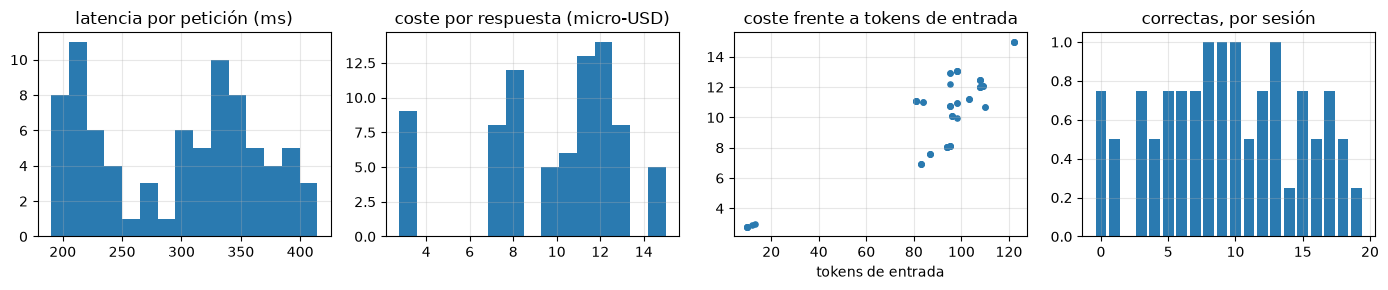

In [7]:
def duration(tr): return tr["end"] - tr["start"]
def gen_of(tr): return next(o for o in children(tr) if o["type"] == "generation")
lat = np.array([duration(t) for t in TRACES])
cost = np.array([gen_of(t)["usage"]["cost"] for t in TRACES])
tok_in = np.array([gen_of(t)["usage"]["input"] for t in TRACES]); tok_out = np.array([gen_of(t)["usage"]["output"] for t in TRACES])
refused = np.array([t["scores"]["refused"] for t in TRACES]); correct = np.array([t["scores"]["correct"] for t in TRACES])
faith = np.array([t["scores"]["faithfulness"] for t in TRACES])

print(f"trazas               {len(TRACES)}")
print(f"latencia p50 / p95  {np.percentile(lat, 50):.0f} / {np.percentile(lat, 95):.0f} ms")
print(f"tokens ent. / sal.   {tok_in.mean():.0f} / {tok_out.mean():.0f} por respuesta (media)")
print(f"coste por respuesta  ${cost.mean():.7f} de media, ${cost.sum():.5f} en total")
print(f"tasa de rechazo       {refused.mean():.1%}")
print(f"correctas             {correct.mean():.1%}   fidelidad media {faith.mean():.2f}")
in_cost = tok_in * PRICES["stand-in-small"][0] / 1e6
print(f"los tokens de entrada son {in_cost.sum() / cost.sum():.0%} del coste; correlación del coste con los tokens de entrada {np.corrcoef(cost, tok_in)[0, 1]:.2f}, con los de salida {np.corrcoef(cost, tok_out)[0, 1]:.2f}")

fig, ax = plt.subplots(1, 4, figsize=(14, 3))
ax[0].hist(lat, bins=15, color="#2a7ab0"); ax[0].set_title("latencia por petición (ms)")
ax[1].hist(cost * 1e6, bins=15, color="#2a7ab0"); ax[1].set_title("coste por respuesta (micro-USD)")
ax[2].scatter(tok_in, cost * 1e6, s=14, color="#2a7ab0"); ax[2].set_xlabel("tokens de entrada"); ax[2].set_title("coste frente a tokens de entrada")
by_session = [np.mean([t["scores"]["correct"] for t in TRACES if t["session"] == f"session-{s:02d}"]) for s in range(20)]
ax[3].bar(range(20), by_session, color="#2a7ab0"); ax[3].set_title("correctas, por sesión"); ax[3].set_ylim(0, 1.05)
for a in ax: a.grid(alpha=.3)
plt.tight_layout(); plt.show()

Tres hábitos que conviene sacar del panel:

1. **Informa de percentiles, no de medias.** El p95 es la experiencia que tiene uno de cada veinte usuarios.
2. **Sabe qué impulsa el coste.** Cada respuesta paga los pasajes que recibió más la respuesta que escribe. En
   esta ejecución, el reparto impreso muestra cuánto viene de la entrada y cuánto de la salida, y cuál de las dos
   sigue más de cerca al coste. Los tokens de salida cuestan más cada uno, así que con un modelo real y más
   locuaz el panorama cambia: registra el reparto con tus propias trazas antes de decidir si recuperar menos
   pasajes o pedir respuestas más cortas.
3. **Una tasa se lee junto a su calidad.** Una tasa de rechazo que baja es buena noticia solo si `correct` y
   `faithfulness` se mantienen; si no, el sistema simplemente ha empezado a adivinar. (Aquí la fidelidad es 1,00
   en todas las respuestas **por construcción**: un generador extractivo solo puede copiar frases que recibió, así
   que esta puntuación no discrimina. Con un modelo real es la puntuación que detecta afirmaciones inventadas.
   Una métrica que nunca se mueve es una métrica de la que hay que dudar.)

## 5. Encontrar las peores trazas

Los agregados te dicen que algo va mal; **las trazas individuales te dicen qué**. Ordena por una puntuación y
abre las malas: obtienes la pregunta, los pasajes que se recuperaron y la respuesta, todo en una pantalla.

In [8]:
bad = [t for t in TRACES if t["scores"]["correct"] == 0]
seen = {}
for t in bad:
    seen.setdefault(t["input"], t)
print(f"{len(bad)} trazas incorrectas, {len(seen)} preguntas distintas:\n")
for question, t in seen.items():
    retr = next(o for o in children(t) if o["name"] == "retrieve")
    print(f"Q: {question}\n   recuperó {[(p, round(s, 1)) for p, s in retr['output']]} (necesitaba {t['fact']!r})\n   A: {t['output']}\n")

28 trazas incorrectas, 9 preguntas distintas:

Q: Are boats cancelled when the sea is too rough?
   recuperó [('p15', 2.6), ('p22', 2.4)] (necesitaba '1.5 m')
   A: Nothing is discharged at sea. [1]

Q: What if the oil in the gearbox gets dirty?
   recuperó [('p07', 6.9), ('p06', 2.7)] (necesitaba 'filter change')
   A: Gearbox oil is sampled every six months. [1]

Q: What do I do if the pitch fault comes back after a reset?
   recuperó [('p10', 8.0), ('p16', 2.2)] (necesitaba 'replace the hydraulic accumulator')
   A: A pitch system fault (code PF-203) usually means a low accumulator pressure. [1]

Q: Can I go up the tower alone to fix something?
   recuperó [('p01', 0.0), ('p02', 0.0)] (necesitaba 'forbidden')
   A: I cannot find that in the handbook.

Q: Who do I call in the middle of the night about an accident?
   recuperó [('p14', 3.0), ('p06', 2.7)] (necesitaba 'control room')
   A: Between October and March, turbines HV01 to HV08 are curtailed at night during the peak migration

Cada fallo es de uno de los dos tipos del módulo 01: o los ids recuperados no incluyen el pasaje que contiene
el dato (un fallo de recuperación, que se arregla con las técnicas del módulo 02 o editando los documentos), o
sí lo incluyen y el generador eligió mal (se arregla en el prompt o en el modelo). Sin la traza solo sabrías que
"respondió mal".

## 6. Lo real: Langfuse

Langfuse es de código abierto, se puede autoalojar o usar como servicio en la nube, y su SDK de Python (versión
5, basado en OpenTelemetry) te da los mismos objetos que nuestro trazador. La celda siguiente es la versión de
producción de las secciones 2 y 3. **No se ejecuta en este notebook**: necesita un proyecto de Langfuse y claves
(`LANGFUSE_PUBLIC_KEY`, `LANGFUSE_SECRET_KEY`, `LANGFUSE_HOST`), y los resultados ejecutados de este curso nunca
dependen de una clave. Con las variables sin definir, la celda solo imprime un mensaje.

In [9]:
import os

if os.getenv("LANGFUSE_PUBLIC_KEY") and os.getenv("LANGFUSE_SECRET_KEY"):
    from langfuse import observe, get_client

    langfuse = get_client()                                   # reads LANGFUSE_* from the environment

    @observe(as_type="generation")                            # a model call: usage and cost are attached to it
    def generate_real(question, passages):
        langfuse.update_current_generation(model="your-model-id", usage_details={"input": 812, "output": 61})
        return "..."

    @observe()                                                # the trace root: nested @observe calls become spans
    def answer_real(question):
        langfuse.update_current_trace(session_id="session-01", user_id="user-17")
        hits = ["..."]
        return generate_real(question, hits)

    answer_real("What wave height stops the crew boats from sailing?")
    # the supervisor of module 08 attaches its verdict later, from another process, by trace id:
    langfuse.create_score(trace_id="<trace id>", name="faithfulness", value=0.92, data_type="NUMERIC", comment="judge: all claims cited")
    langfuse.flush()                                          # send pending events before the process exits
else:
    print("LANGFUSE_* sin definir: se omitió la celda del SDK real (es el estado esperado en el curso).")

LANGFUSE_* sin definir: se omitió la celda del SDK real (es el estado esperado en el curso).


Dos integraciones importan más que el decorador, porque trazan código que tú no escribiste:

* **LiteLLM** (módulo 04): `litellm.success_callback = ["langfuse"]` y `litellm.failure_callback = ["langfuse"]`
  registran cada llamada a un modelo que pase por él, con modelo, tokens y coste, sea cual sea el proveedor detrás.
* **LangChain y LangGraph** (módulos 03 y 05): pasa `from langfuse.langchain import CallbackHandler` como callback
  en `config={"callbacks": [handler]}` de la llamada y cada paso de la cadena, cada llamada al recuperador y cada
  llamada al modelo se convierte en una observación anidada.

En el agente de analítica de parques eólicos de este portafolio, Langfuse se conectó exactamente así: a través del
enrutador LiteLLM y de los callbacks de LangChain, con el trazado desactivado cuando no hay claves configuradas,
de modo que la aplicación funciona igual con él o sin él.

## 7. LangSmith, y por qué no lo usamos

**LangSmith** es el producto de trazado, evaluación y conjuntos de datos de los creadores de LangChain. Hace el
mismo trabajo básico que Langfuse (trazas, ejecuciones, puntuaciones de feedback) y añade catálogos de prompts y
ejecuciones de evaluación guiadas por conjuntos de datos, estrechamente integrados con LangChain y LangGraph.

| | Langfuse | LangSmith |
|---|---|---|
| Licencia y alojamiento | código abierto, autoalojable o en la nube | producto alojado (el autoalojamiento es una opción empresarial) |
| Encaje con frameworks | cualquier código, más LiteLLM, LangChain, SDK estilo OpenAI, OpenTelemetry | diseñado en torno a LangChain y LangGraph, funciona con otros |
| Trazas, puntuaciones, sesiones | sí | sí (ejecuciones, feedback, hilos) |
| Conjuntos de datos y experimentos | sí | sí, un punto fuerte |
| Gestión de prompts | sí | sí (catálogo de prompts) |
| Usado en este portafolio | **sí** | **no** |

**La razón honesta por la que no usamos LangSmith:** Langfuse ya cubría el trazado, y una segunda pila habría
supuesto otra cuenta externa, otro juego de claves y otro lugar donde guardar prompts y respuestas, sin ninguna
ganancia funcional. No hay nada malo en LangSmith; para un equipo totalmente centrado en LangChain y que quiera su
flujo de evaluación alojado es una primera opción razonable. Elige según dónde pueden vivir tus datos, cómo llama
tu código a los modelos y qué ejecutas ya, y recuerda que, como ambas hablan en trazas, tramos y puntuaciones,
pasar de una a otra es un cambio pequeño en la capa de instrumentación, no una reescritura.

En este curso no se ejecuta código de LangSmith, por la misma razón.

## Ejercicios

1. Añade a la generación un campo `retrieved_ids` y una puntuación `hit` (¿está el pasaje de referencia entre
   ellos?). Después dibuja `hit` frente a `correct` sobre las trazas. ¿Qué dice la tabla cruzada sobre de dónde
   vienen los fallos?
2. Cambia `PRICES` a diez veces el precio de salida. ¿Cómo se mueve el coste por respuesta y qué lado domina
   ahora? Después cambia `k` en `retrieve` de 2 a 4: ¿cuánto se mueve el coste y cómo cambia `correct`?
3. Haz que el generador de sustitución lance de vez en cuando una excepción. ¿Dónde necesitaría tu trazador un
   campo `status` para que las llamadas fallidas aparezcan en el panel en lugar de desaparecer?
4. Registra una puntuación de sesión: la proporción de trazas de una sesión que fueron rechazos. ¿Qué sesiones
   abrirías primero y qué buscarías?